# Stochastic System Problem Set Solutions (`lec_sde.pdf` Exercises)

**References:** `Notes/lec_sde.pdf` (Final Slide — Exercises 1 & 2), `Notes/Quiz2/06_Random_Walks_1D_and_2D.ipynb`

Grouped by question type:
1. **Type 1:** 2D Unbiased Random Walk vs. 1D Random Walk (`lec_sde.pdf` Exercise 1)
2. **Type 2:** 1D Biased Random Walk (`lec_sde.pdf` Exercise 2)

---
## Type 1: 2D Random Walk (`lec_sde.pdf` Exercise 1)
Displacement vector: $\mathbf{R}_n = x_n \hat{i} + y_n \hat{j}$ with independent $\pm 1$ steps along $x$ and $y$.

- **(i) Analytical Results:**
  - Average displacement: $\langle \mathbf{R}_n \rangle = \langle x_n \rangle \hat{i} + \langle y_n \rangle \hat{j} = 0\hat{i} + 0\hat{j} = \mathbf{0}$.
  - Mean-squared displacement: $\langle R_n^2 \rangle = \langle x_n^2 + y_n^2 \rangle = \langle x_n^2 \rangle + \langle y_n^2 \rangle = n + n = 2n$.
- **(iii) Comparison with 1D:** In 1D, $\langle x_n^2 \rangle = n$. In 2D, $\langle R_n^2 \rangle = 2n$ (twice as large because diffusion occurs independently in $d = 2$ orthogonal directions: $\langle R_n^2 \rangle = d \cdot n$).

Final <Rx> = -0.23, <Ry> = -0.44 (Theory: 0)
Final 1D MSD = 2148.2 (Theory: 1999)
Final 2D MSD = 4091.6 (Theory: 3998)


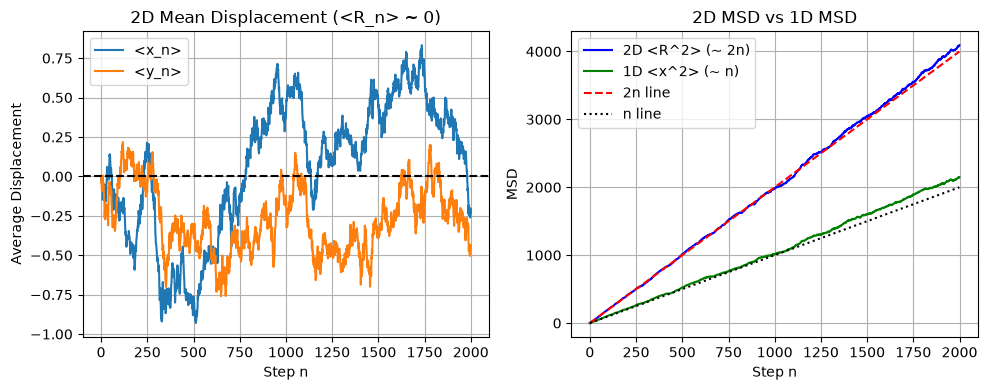

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Exercise 1 (ii) & (iii): Numerical check of <R_n> and <R_n^2> vs 1D <x_n^2>
N = 2000
Nre = 1000

X_all = np.zeros((N, Nre))
Y_all = np.zeros((N, Nre))

for ire in range(Nre):
    sx = np.where(np.random.rand(N) >= 0.5, 1, -1); sx[0] = 0
    sy = np.where(np.random.rand(N) >= 0.5, 1, -1); sy[0] = 0
    X_all[:, ire] = np.cumsum(sx)
    Y_all[:, ire] = np.cumsum(sy)

avg_Rx = np.mean(X_all, axis=1)
avg_Ry = np.mean(Y_all, axis=1)
msd_1d = np.mean(X_all**2, axis=1)
msd_2d = np.mean(X_all**2 + Y_all**2, axis=1)
steps = np.arange(N)

print(f'Final <Rx> = {avg_Rx[-1]:.2f}, <Ry> = {avg_Ry[-1]:.2f} (Theory: 0)')
print(f'Final 1D MSD = {msd_1d[-1]:.1f} (Theory: {N-1})')
print(f'Final 2D MSD = {msd_2d[-1]:.1f} (Theory: {2*(N-1)})')

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(steps, avg_Rx, label='<x_n>')
plt.plot(steps, avg_Ry, label='<y_n>')
plt.axhline(0, color='k', linestyle='--')
plt.xlabel('Step n'); plt.ylabel('Average Displacement')
plt.title('2D Mean Displacement (<R_n> ~ 0)')
plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(steps, msd_2d, 'b-', label='2D <R^2> (~ 2n)')
plt.plot(steps, msd_1d, 'g-', label='1D <x^2> (~ n)')
plt.plot(steps, 2 * steps, 'r--', label='2n line')
plt.plot(steps, steps, 'k:', label='n line')
plt.xlabel('Step n'); plt.ylabel('MSD')
plt.title('2D MSD vs 1D MSD')
plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

---
## Type 2: 1D Biased Random Walk (`lec_sde.pdf` Exercise 2)
Recurrence: $x_n = x_{n-1} + \xi_n$, where $\xi_n = +1$ with $p = 2/3$ and $-1$ with $q = 1/3$.

### (ii) Analytical Derivation
- **Mean step:** $\langle \xi_n \rangle = (+1)\frac{2}{3} + (-1)\frac{1}{3} = \frac{1}{3}$.
- **(a) Average displacement:** $\langle x_n \rangle = \sum_{k=1}^n \langle \xi_k \rangle = \frac{n}{3}$.
- **(c) Shifted MSD (Variance):** $\text{Var}(\xi_n) = \langle \xi_n^2 \rangle - \langle \xi_n \rangle^2 = 1 - \frac{1}{9} = \frac{8}{9}$ (same as $4pq = \frac{8}{9}$). Since steps are independent:
  $$\langle (x_n - \langle x_n \rangle)^2 \rangle = \frac{8}{9} n$$
- **(b) Unshifted MSD:**
  $$\langle x_n^2 \rangle = \langle (x_n - \langle x_n \rangle)^2 \rangle + \langle x_n \rangle^2 = \frac{8}{9}n + \frac{n^2}{9}$$

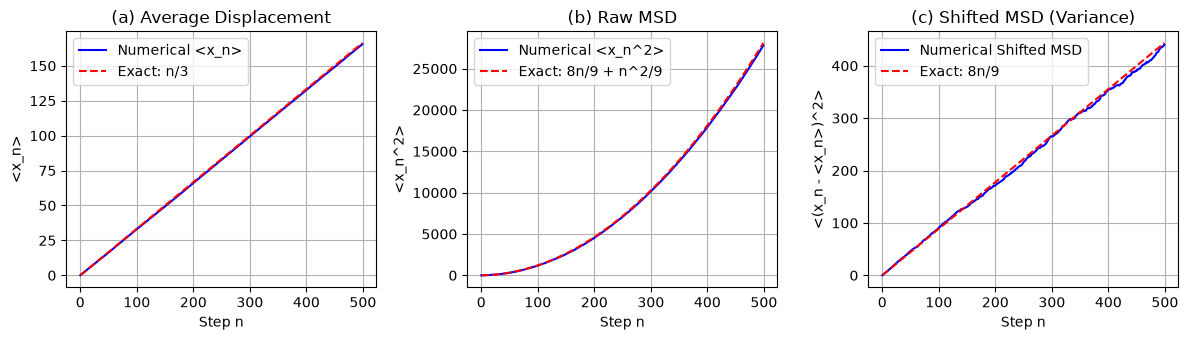

In [2]:
# Exercise 2 (i): Biased 1D Random Walk with p = 2/3 (+1), q = 1/3 (-1)
N = 500
Nre = 2000
p = 2.0 / 3.0

X_bias = np.zeros((N, Nre))
for ire in range(Nre):
    steps = np.where(np.random.rand(N) < p, 1, -1)
    steps[0] = 0
    X_bias[:, ire] = np.cumsum(steps)

n_axis = np.arange(N)
avg_x = np.mean(X_bias, axis=1)
msd_x = np.mean(X_bias**2, axis=1)
shifted_msd = np.mean((X_bias - avg_x[:, None])**2, axis=1)

plt.figure(figsize=(12, 3.5))

plt.subplot(1, 3, 1)
plt.plot(n_axis, avg_x, 'b-', label='Numerical <x_n>')
plt.plot(n_axis, n_axis / 3.0, 'r--', label='Exact: n/3')
plt.xlabel('Step n'); plt.ylabel('<x_n>')
plt.title('(a) Average Displacement')
plt.legend(); plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(n_axis, msd_x, 'b-', label='Numerical <x_n^2>')
plt.plot(n_axis, (8.0/9.0)*n_axis + (n_axis**2)/9.0, 'r--', label='Exact: 8n/9 + n^2/9')
plt.xlabel('Step n'); plt.ylabel('<x_n^2>')
plt.title('(b) Raw MSD')
plt.legend(); plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(n_axis, shifted_msd, 'b-', label='Numerical Shifted MSD')
plt.plot(n_axis, (8.0/9.0)*n_axis, 'r--', label='Exact: 8n/9')
plt.xlabel('Step n'); plt.ylabel('<(x_n - <x_n>)^2>')
plt.title('(c) Shifted MSD (Variance)')
plt.legend(); plt.grid(True)

plt.tight_layout()
plt.show()